<a href="https://colab.research.google.com/github/prathik002/DataScience-Lab/blob/main/Program_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Housing.csv to Housing (2).csv
First Five Rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Dataset Shape:
(545, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Statistical Summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


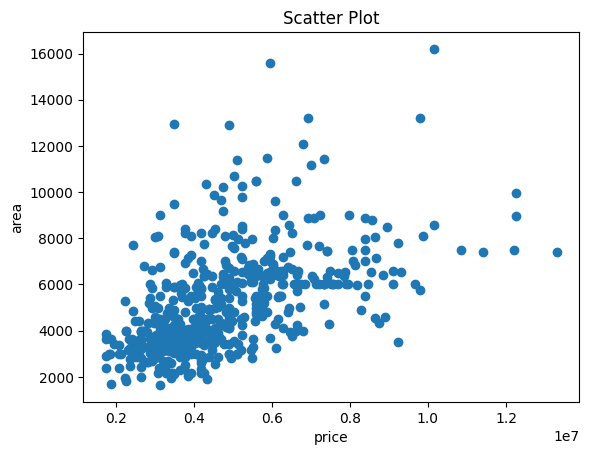

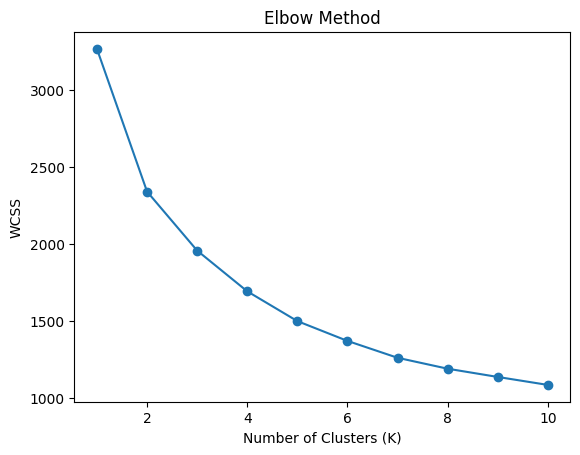


Clustered Data:


,price,area,bedrooms,bathrooms,stories,parking,Cluster
0,13300000,7420,4,2,3,2,2
1,12250000,8960,4,4,4,3,2
2,12250000,9960,3,2,2,2,2
3,12215000,7500,4,2,2,3,2
4,11410000,7420,4,1,2,2,2


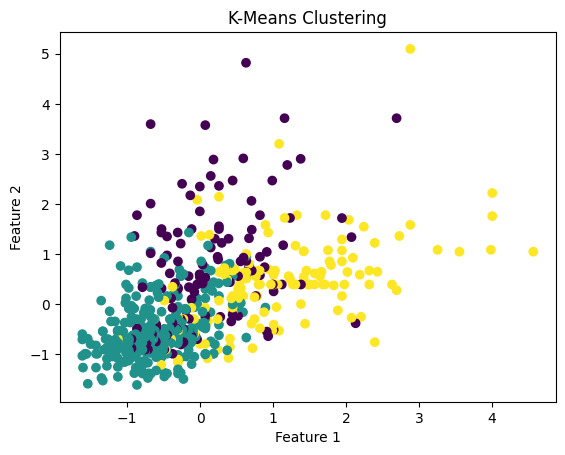

In [2]:
'''Program 22: Dataset: <Housing_Price.csv>
a) Conduct exploratory data analysis on the given dataset and report
the details.
b) Visualize the analysis results using (i) scatter plot (ii) histogram & (iii)
box plot.
c) Implement the K-Means clustering algorithm using the dataset. Try
with different k values and plot the elbow graph for the k values.'''


# Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from google.colab import files

# Step 2: Upload Dataset
uploaded = files.upload()
df = pd.read_csv('/content/Housing.csv')

# Step 3: EDA
print("First Five Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

# Step 4: Select Numerical Columns
data = df.select_dtypes(include='number')
data = data.dropna()

# Remove constant columns
data = data.loc[:, data.nunique() > 1]

# Step 5: Scatter Plot
plt.scatter(data.iloc[:, 0], data.iloc[:, 1])
plt.xlabel(data.columns[0])
plt.ylabel(data.columns[1])
plt.title("Scatter Plot")
plt.show()

# Step 6: Standardize Data
scaler = StandardScaler()
X = scaler.fit_transform(data)

# Step 7: Elbow Method
wcss = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

# Step 8: Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Step 9: K-Means Clustering (K = 3)
km = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = km.fit_predict(X)

data = data.copy()
data['Cluster'] = clusters

print("\nClustered Data:")
display(data.head())

# Step 10: Plot Clusters
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.show()
